In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
#df=pd.read_excel("cgpaPRED.xls")   

In [3]:
#df.to_csv("cgpaPRED.csv",index=False)

In [4]:
df=pd.read_csv("cgpaPRED.csv")

In [5]:
df

,SEM 1,SEM 2,SEM 3,SEM 4,SEM 5
0,6.60,7.60,6.90,7.22,7.08
1,7.77,7.22,7.00,7.90,7.47
2,6.90,6.00,7.12,7.54,6.89
3,5.50,6.60,6.70,6.50,6.33
4,7.20,6.00,7.21,7.70,7.03
...,...,...,...,...,...
326,0.54,0.78,0.45,0.98,0.69
327,0.80,0.19,0.52,0.83,0.59
328,0.88,0.78,0.43,0.32,0.60
329,4.23,4.32,4.96,4.39,4.48


In [6]:
df.columns

Index(['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4', 'SEM 5'], dtype='object')

# Understanding the dataset
The dataset cgpaPRED.csv have a total of 5 columns out of which 4 are input features('SEM 1', 'SEM 2', 'SEM 3', 'SEM 4') and 1 output feature('SEM 5). 
There are around 48 rows which are repeted, So we need to remove so that we do not face any problem

In [7]:
df.drop_duplicates()

,SEM 1,SEM 2,SEM 3,SEM 4,SEM 5
0,6.60,7.60,6.90,7.22,7.08
1,7.77,7.22,7.00,7.90,7.47
2,6.90,6.00,7.12,7.54,6.89
3,5.50,6.60,6.70,6.50,6.33
4,7.20,6.00,7.21,7.70,7.03
...,...,...,...,...,...
326,0.54,0.78,0.45,0.98,0.69
327,0.80,0.19,0.52,0.83,0.59
328,0.88,0.78,0.43,0.32,0.60
329,4.23,4.32,4.96,4.39,4.48


In [8]:
df

,SEM 1,SEM 2,SEM 3,SEM 4,SEM 5
0,6.60,7.60,6.90,7.22,7.08
1,7.77,7.22,7.00,7.90,7.47
2,6.90,6.00,7.12,7.54,6.89
3,5.50,6.60,6.70,6.50,6.33
4,7.20,6.00,7.21,7.70,7.03
...,...,...,...,...,...
326,0.54,0.78,0.45,0.98,0.69
327,0.80,0.19,0.52,0.83,0.59
328,0.88,0.78,0.43,0.32,0.60
329,4.23,4.32,4.96,4.39,4.48


In [ ]:
df.notna().sum()

SEM 1    331
SEM 2    331
SEM 3    331
SEM 4    331
SEM 5    331
dtype: int64

In [32]:
df.isnull().sum()

SEM 1    0
SEM 2    0
SEM 3    0
SEM 4    0
SEM 5    0
dtype: int64

# VISUALIZATION

In [9]:
a = df["SEM 1"]
b = df["SEM 5"]

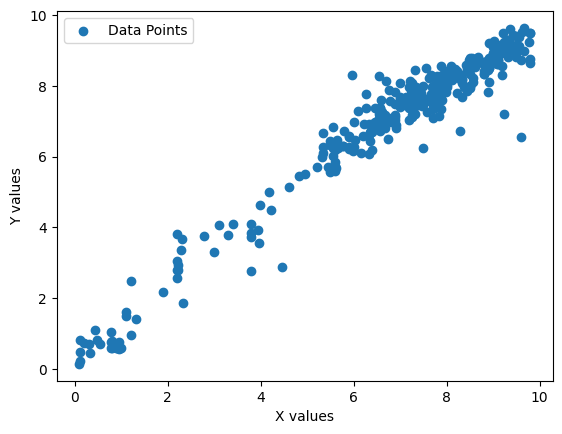

In [10]:
plt.scatter(a,b,label='Data Points')
plt.xlabel("X values")
plt.ylabel("Y values")
plt.legend()
plt.show()

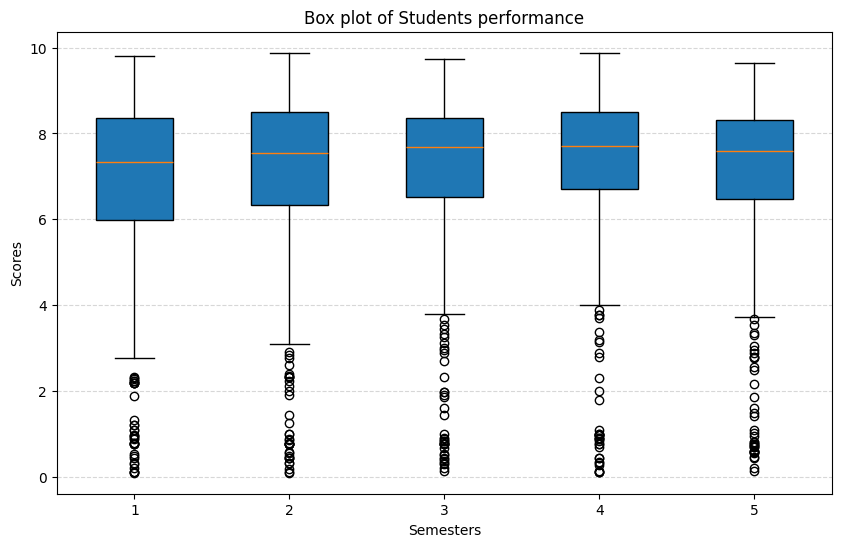

In [11]:
semesterCols = ["SEM 1", "SEM 2", "SEM 3", "SEM 4", "SEM 5"]
dataToPolot = [df[col].dropna() for col in semesterCols]
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(dataToPolot, label=semesterCols, patch_artist=True)
ax.set_title("Box plot of Students performance")
ax.set_xlabel("Semesters")
ax.set_ylabel("Scores")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

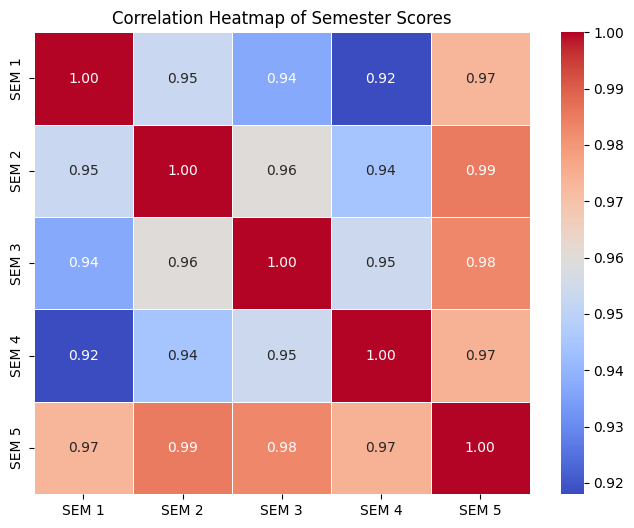

In [37]:
semesterCols = ["SEM 1", "SEM 2", "SEM 3", "SEM 4", "SEM 5"]

corrMatrix = df[semesterCols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corrMatrix,
    annot=True,      # show correlation values
    cmap="coolwarm", # color scheme
    fmt=".2f",       # 2 decimal places
    linewidths=0.5
)

plt.title("Correlation Heatmap of Semester Scores")
plt.show()

# CODE OF LINEAR REGRESSION

In [12]:
X = df[['SEM 1']]
y = df["SEM 5"]

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [14]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [15]:
y_pred = model.predict(X_test)

In [16]:
print("\nRegression Equation:")

print(
    f"Y = {model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f}X1"
)


Regression Equation:
Y = 0.68 + 0.92X1


In [17]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

if len(y_test) > 1:
    r2 = r2_score(y_test, y_pred)
else:
    r2 = 0

In [18]:
print("MODEL PERFORMANCE")

print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MODEL PERFORMANCE
MSE  : 0.1842
MAE  : 0.3209
RMSE : 0.4292
R²   : 0.9676


# CODE OF MULTIPLE LINEAR REGRESSION

In [19]:
X = df[['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4']]
y = df["SEM 5"]


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [21]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [22]:
y_pred = model.predict(X_test)

In [23]:
print("Regression Equation:")

print(
    f"Y = {model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f}X1 + "
    f"{model.coef_[1]:.2f}X2 + "
    f"{model.coef_[2]:.2f}X3 + "
    f"{model.coef_[3]:.2f}X3"
    
)

Regression Equation:
Y = 0.00 + 0.25X1 + 0.25X2 + 0.25X3 + 0.25X3


In [24]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

if len(y_test) > 1:
    r2 = r2_score(y_test, y_pred)
else:
    r2 = 0

In [25]:
print("MODEL PERFORMANCE")
print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MODEL PERFORMANCE
MSE  : 0.0000
MAE  : 0.0026
RMSE : 0.0029
R²   : 1.0000
